In [6]:
import pandas as pd 
import matplotlib.pyplot as plt 

df = pd.read_csv(
  "../data/raw/gatun_weather_daily.csv",
  parse_dates=["date"],
  index_col="date"
)

            rainfall_mm
date                   
1981-01-01        30.35
1981-02-01        68.20
1981-03-01        74.61
1981-04-01       188.08
1981-05-01       259.05
Meses incompletos: 0


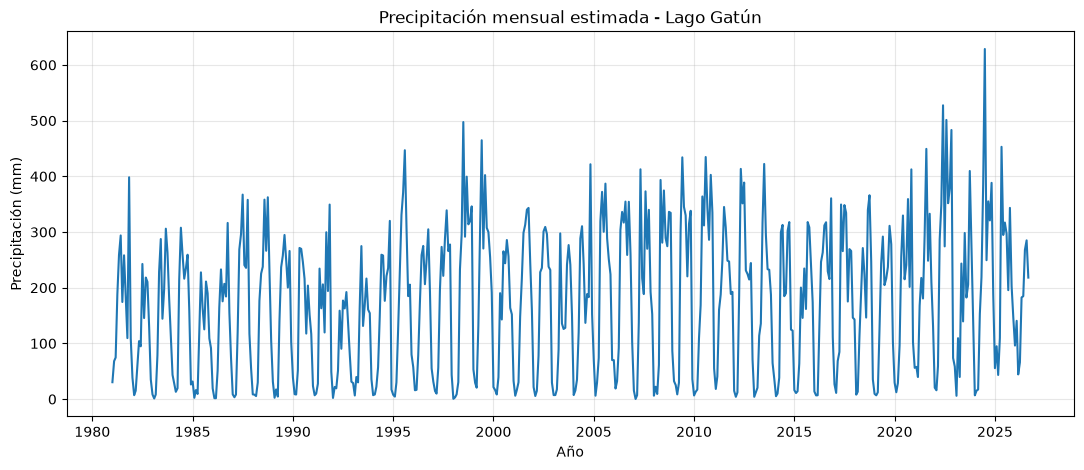

In [ ]:
# Verificando que todos los meses tengan los dias validos 

# Agrupación de los meses (registros del 01-31 se agrupan bajo fecha Ej. 2026-01-01)
# Porque sumar precipitaciones de un mes incompleto podría producir un total artificialmente bajo.
# Por ejemplo, si faltan cinco días de lluvia intensa, el total mensual estaría subestimado.
monthly = df["precip_mm_day"].resample("MS").agg(
  ["sum","count","size"]
)

# Creando nueva columna rainfall_mm, que solo conserva el valor de sum cuando se cumpla la condición count = size 
monthly["rainfall_mm"] = monthly["sum"].where(
  monthly["count"] == monthly["size"]
)
# monthly["rainfall_mm"] elimina las columnas auxiliares sum, count, size. Y solo conserva el total de lluvia mensual. 
monthly = monthly[["rainfall_mm"]]

print(monthly.head()) # muestra las 5 primeras filas de la tabla 
print("Meses incompletos:", monthly.isna().sum().iloc[0]) #isna() identifica los meses faltantes y el sum() los suma. i[0] conteo de la primera columna 

monthly.to_csv("../data/processed/gatun_monthly.csv") # Guardado de datos.

# Grafico historico de las precipitaciones. 
plt.figure(figsize=(13,5)) # Creación de cuadricula 13 x 5 pulgadas
plt.plot(monthly.index, monthly["rainfall_mm"]) # Fechas en eje x y precipitaciones por mes en eje Y
plt.title("Precipitación mensual estimada - Lago Gatún")
plt.xlabel("Año")
plt.ylabel("Precipitación (mm)")
plt.grid(alpha=0.3) # Cuadricula Tenue. 
plt.show()



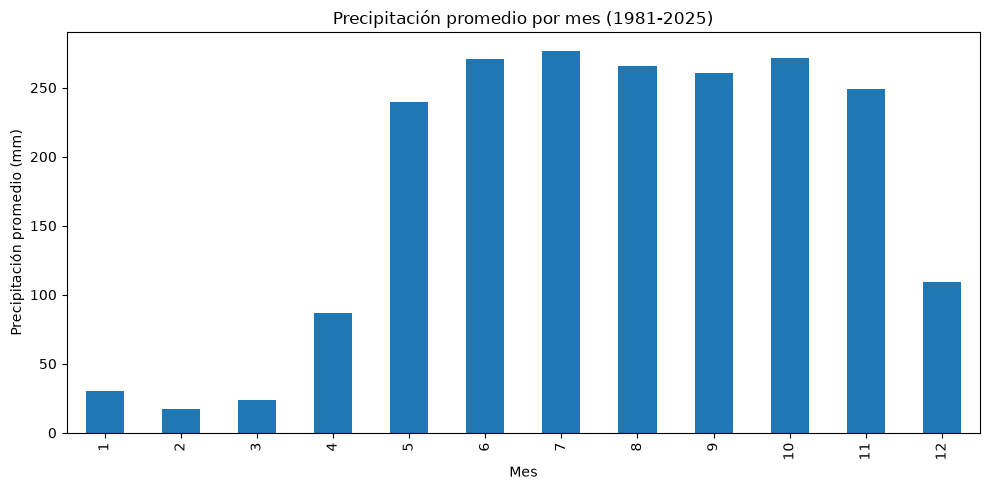

In [ ]:
monthly["month"] = monthly.index.month #Numero de meses por fecha. 

climatology = monthly.groupby("month")["rainfall_mm"].mean() # groupby("month") agrupa todos los eneros, etc. ["rainfall_mm"].mean() calcula el promedio de preci. en mm por mes

plt.figure(figsize=(10, 5))
climatology.plot(kind="bar") # grafica de barra
plt.title("Precipitación promedio por mes (1981-2025)")
plt.xlabel("Mes")
plt.ylabel("Precipitación promedio (mm)")
plt.tight_layout() # Se ajustan los espacios del gráfico para reducir superposiciones de textos y etiquetas.
plt.show()


In [9]:

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv(
    "../data/processed/gatun_monthly.csv",
    parse_dates=["date"],
    index_col="date"
)

# Variables conocidas antes del mes objetivo
df["lag_1"] = df["rainfall_mm"].shift(1)
df["lag_2"] = df["rainfall_mm"].shift(2)
df["lag_3"] = df["rainfall_mm"].shift(3)
df["lag_12"] = df["rainfall_mm"].shift(12)

df["month_sin"] = np.sin(2 * np.pi * df.index.month / 12)
df["month_cos"] = np.cos(2 * np.pi * df.index.month / 12)

features = [
    "lag_1", "lag_2", "lag_3", "lag_12",
    "month_sin", "month_cos"
]

df = df.dropna(subset=features + ["rainfall_mm"])

# División cronológica
train = df.loc[: "2019-12-01"]
validation = df.loc["2020-01-01":"2022-12-01"]
test = df.loc["2023-01-01":"2025-12-01"]

model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(train[features], train["rainfall_mm"])

# Validación para ajustar el modelo
val_pred = model.predict(validation[features])

# Evaluación final sin ajustar sobre test
pred = model.predict(test[features])

# Modelo base: lluvia del mismo mes del año anterior
baseline = test["lag_12"]

for name, predictions in [
    ("Baseline estacional", baseline),
    ("Random Forest", pred)
]:
    mae = mean_absolute_error(test["rainfall_mm"], predictions)
    rmse = np.sqrt(
        mean_squared_error(test["rainfall_mm"], predictions)
    )
    print(f"{name}: MAE={mae:.2f} mm | RMSE={rmse:.2f} mm")


Baseline estacional: MAE=118.45 mm | RMSE=156.49 mm
Random Forest: MAE=72.35 mm | RMSE=99.41 mm
